# Path Reproduction — physical robot vs Digital Twin

Group project 04 *Path Reproduction* (Motors · odometry). One designed path with straights, a wide and a tight
arc, on-the-spot rotations in both directions, a reversal and four speed levels is run

* on the **real robot** — firmware `05_path_reproduction/Path_Reproduction/`, encoder closed loop, logs every 20 ms;
* in the **Digital Twin** — the supplied Processing twin extended in `05_path_reproduction/DigitalTwin_PathReproduction/`,
  and the same model in Python (`twin/twin.py`), both running **the same controller code** as the robot.

Two twin models are compared with the robot:

| model | motors | geometry | source |
|---|---|---|---|
| `course` | PWM → speed linear (PWM 200 = 0.25 mm/ms), wheels identical, no deadband, no lag | B = 90 mm, r = 16 mm | the supplied twin |
| `calibrated` | per-wheel gain above a deadband, first-order lag, right-wheel delay, integer PWM | B = 83.48 mm, r = 16.36 mm | fitted to this robot's Ex2–Ex4 logs |

Questions: where and when do real and twin trajectories begin to diverge, which motion types produce the largest
differences, and which model assumptions explain them?

> Real runs are read from `data/real/path_t*.csv` (from `Path_Reproduction/wifi_logger.py`). Until they exist, the
> real-vs-twin cells say so and the notebook compares the two twins with each other.

In [1]:
import os, sys, glob, math, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO_URL = "https://github.com/comradeofjustice/Bristol_odometry"
if os.path.isdir("05_path_reproduction"):
    BASE = "05_path_reproduction"
elif os.path.isdir("../twin"):
    BASE = ".."
else:
    if not os.path.isdir("Bristol_odometry"):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    BASE = "Bristol_odometry/05_path_reproduction"
sys.path.insert(0, f"{BASE}/twin")
import twin, compare
print("project folder:", BASE)

project folder: Bristol_odometry/05_path_reproduction


## 1. The designed path

In [2]:
seg_table = []
for i, (seg, name, kind) in enumerate(zip(twin.PATH, twin.SEGMENT_NAMES, twin.SEGMENT_KIND), start=1):
    sl, sr = twin.wheel_distances(seg)
    seg_table.append({"segment": i, "name": name, "kind": kind, "max_pwm": seg[3],
                      "left_wheel_mm": round(sl, 1), "right_wheel_mm": round(sr, 1)})
seg_table = pd.DataFrame(seg_table)
nominal = twin.nominal_path()
print(f"designed path closes at ({nominal.x_mm.iloc[-1]:.2f}, {nominal.y_mm.iloc[-1]:.2f}) mm, "
      f"{math.degrees(nominal.theta_rad.iloc[-1]):.1f} deg")
seg_table

designed path closes at (-0.00, 0.00) mm, 360.0 deg


,segment,name,kind,max_pwm,left_wheel_mm,right_wheel_mm
0,1,straight 200 slow,straight,30.0,200.0,200.0
1,2,arc L R80 180,arc,35.0,120.2,382.5
2,3,straight 100 fast,straight,50.0,100.0,100.0
3,4,rotate CW 90,rotate,35.0,65.6,-65.6
4,5,reverse 100,reverse,35.0,-100.0,-100.0
5,6,rotate CCW 90,rotate,35.0,-65.6,65.6
6,7,straight 100,straight,40.0,100.0,100.0
7,8,arc L R60 90 (tight),arc,35.0,28.7,159.8
8,9,rotate CCW 90,rotate,35.0,-65.6,65.6
9,10,straight 60 slow,straight,30.0,60.0,60.0


## 2. Run both twins (Python) and check them against the Processing twin

In [3]:
runs = {name: twin.run(name) for name in twin.MODELS}
for name, df in runs.items():
    last = df.iloc[-1]
    print(f"{name:10s} {df.time_ms.iloc[-1]/1000:5.1f} s   true end ({last.x_true_mm:6.1f}, {last.y_true_mm:6.1f}) mm, "
          f"{math.degrees(last.theta_true_rad):6.1f} deg   robot odometry end ({last.x_mm:6.1f}, {last.y_mm:6.1f})")

# The Processing sketch writes twin_<model>_processing.csv on start-up; a copy is kept in data/twin/.
for name in twin.MODELS:
    path = f"{BASE}/data/twin/twin_{name}_processing.csv"
    if os.path.isfile(path):
        p = pd.read_csv(path)
        n = min(len(p), len(runs[name]))
        d = np.hypot(p.x_true_mm[:n] - runs[name].x_true_mm[:n], p.y_true_mm[:n] - runs[name].y_true_mm[:n])
        print(f"Processing vs Python ({name}): {len(p)} vs {len(runs[name])} rows, max position difference {d.max():.1f} mm")

course      35.3 s   true end (  -9.1,   67.2) mm,  325.1 deg   robot odometry end (  -1.5,    5.9)
calibrated  30.3 s   true end (   2.1,   -1.9) mm,  362.2 deg   robot odometry end (   2.2,   -1.7)
Processing vs Python (course): 1764 vs 1764 rows, max position difference 1.1 mm
Processing vs Python (calibrated): 1516 vs 1517 rows, max position difference 4.4 mm


## 3. Real robot runs

In [4]:
real_files = sorted(glob.glob(f"{BASE}/data/real/path_t*.csv"))
real = {os.path.basename(f)[:-4]: pd.read_csv(f) for f in real_files}
if real:
    for k, df in real.items():
        last = df.iloc[-1]
        print(f"{k}: {len(df)} rows, {df.time_ms.iloc[-1]/1000:.1f} s, segments {df.segment.max()}, "
              f"odometry end ({last.x_mm:.1f}, {last.y_mm:.1f}) mm, {math.degrees(last.theta_rad):.1f} deg")
else:
    print("No real runs yet: copy Path_Reproduction/logs/path_t*.csv into data/real/ and run again.")
    print("Until then the comparisons below use the calibrated twin as the reference and the course twin as the model.")
REF_NAME = "real (mean)" if real else "calibrated twin"

No real runs yet: copy Path_Reproduction/logs/path_t*.csv into data/real/ and run again.
Until then the comparisons below use the calibrated twin as the reference and the course twin as the model.


## 4. Trajectories

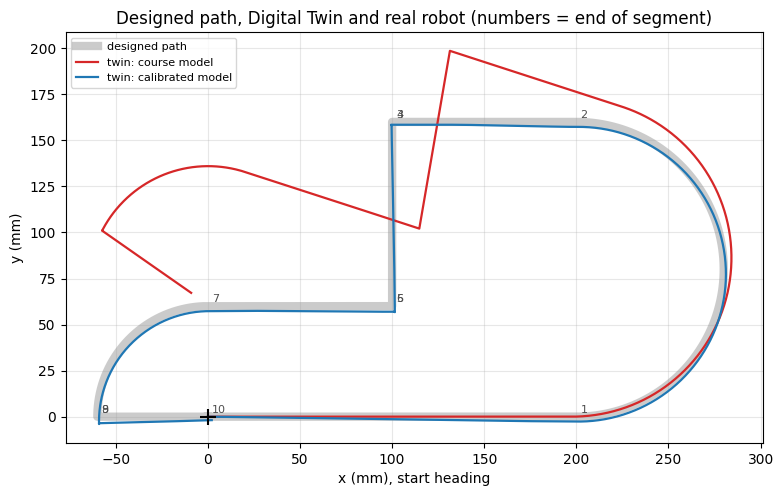

In [5]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(nominal.x_mm, nominal.y_mm, color="0.6", lw=6, alpha=0.5, label="designed path")
ax.plot(runs["course"].x_true_mm, runs["course"].y_true_mm, color="C3", lw=1.6, label="twin: course model")
ax.plot(runs["calibrated"].x_true_mm, runs["calibrated"].y_true_mm, color="C0", lw=1.6, label="twin: calibrated model")
for k, df in real.items():
    ax.plot(df.x_mm, df.y_mm, color="C1", lw=1.2, alpha=0.8, label=f"real {k} (robot odometry)")
for i, row in nominal.groupby("segment").last().iterrows():
    if i >= 1:
        ax.annotate(str(i), (row.x_mm, row.y_mm), fontsize=8, color="0.3", xytext=(3, 3), textcoords="offset points")
ax.scatter([0], [0], marker="+", s=120, color="k", zorder=5)
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="upper left")
ax.set_xlabel("x (mm), start heading"); ax.set_ylabel("y (mm)")
ax.set_title("Designed path, Digital Twin and real robot (numbers = end of segment)")
os.makedirs(f"{BASE}/analysis", exist_ok=True)
plt.savefig(f"{BASE}/analysis/trajectories.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Where and when do the trajectories diverge?

Two alignments: **by time** (same time since start — includes speed/timing differences) and **by progress**
(same fraction of each segment — isolates the geometry of the motion). Reference = real robot odometry when
available, otherwise the calibrated twin.

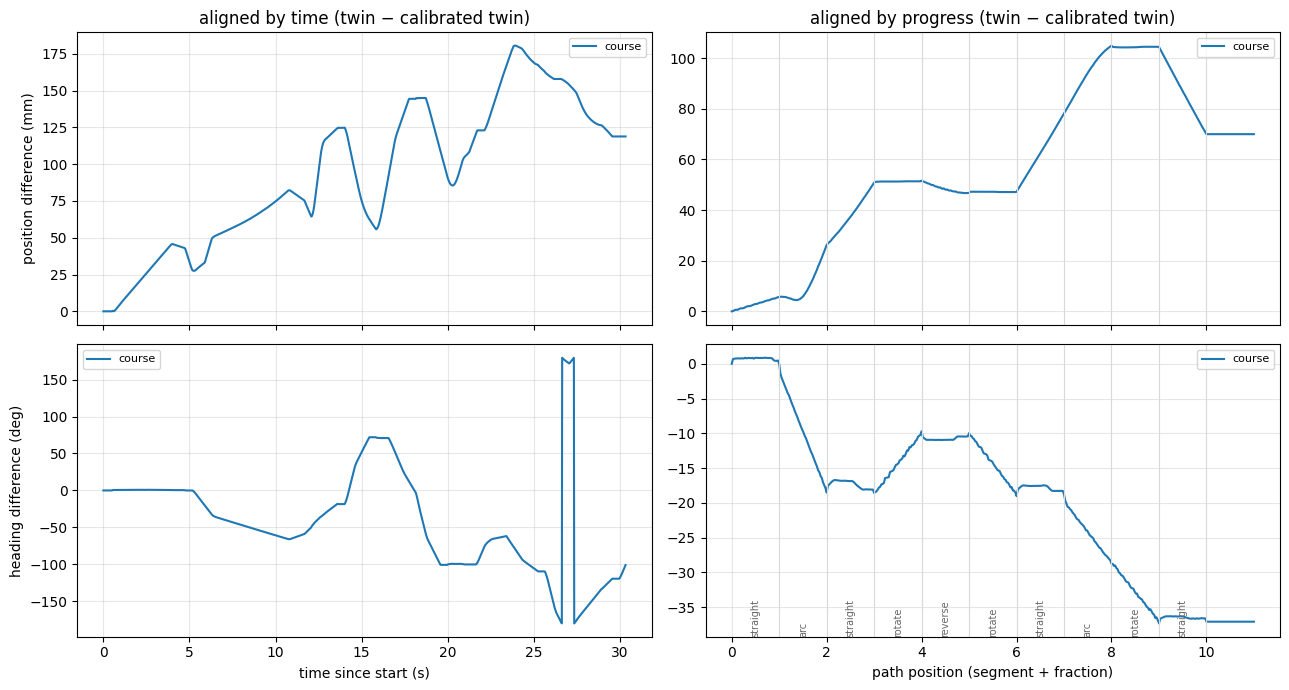

course: divergence onset (time-aligned) {'position': {'threshold': 5.0, 'time_ms': 980.0, 'segment': 1}, 'heading': {'threshold': 2.0, 'time_ms': 5280.0, 'segment': 2}}


In [6]:
cols_true = ("x_true_mm", "y_true_mm", "theta_true_rad")
cols_odo = ("x_mm", "y_mm", "theta_rad")
if real:
    ref = list(real.values())[0]; ref_cols = cols_odo; twin_cols = cols_odo   # like for like: odometry vs odometry
    models = {"course": runs["course"], "calibrated": runs["calibrated"]}
else:
    ref = runs["calibrated"]; ref_cols = cols_true; twin_cols = cols_true
    models = {"course": runs["course"]}

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex="col")
onsets = {}
for name, df in models.items():
    at = compare.align_by_time(ref, df, ref_cols, twin_cols)
    ap = compare.align_by_progress(ref, df, ref_cols, twin_cols)
    onsets[name] = compare.divergence_onset(at)
    axes[0, 0].plot(at.time_ms / 1000, at.dpos_mm, label=name)
    axes[1, 0].plot(at.time_ms / 1000, at.dth_deg, label=name)
    axes[0, 1].plot(ap.s, ap.dpos_mm, label=name)
    axes[1, 1].plot(ap.s, ap.dth_deg, label=name)
for s in range(1, len(twin.PATH) + 1):
    for a in axes[:, 1]:
        a.axvline(s, color="0.85", lw=0.8)
for k, kind in enumerate(twin.SEGMENT_KIND):
    axes[1, 1].text(k + 0.5, axes[1, 1].get_ylim()[0], kind, rotation=90, fontsize=7, ha="center", va="bottom", color="0.4")
axes[0, 0].set_ylabel("position difference (mm)"); axes[1, 0].set_ylabel("heading difference (deg)")
axes[1, 0].set_xlabel("time since start (s)"); axes[1, 1].set_xlabel("path position (segment + fraction)")
axes[0, 0].set_title(f"aligned by time (twin − {REF_NAME})"); axes[0, 1].set_title(f"aligned by progress (twin − {REF_NAME})")
for a in axes.flat:
    a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{BASE}/analysis/divergence.png", dpi=120, bbox_inches="tight")
plt.show()
for name, o in onsets.items():
    print(f"{name}: divergence onset (time-aligned) {o}")

## 6. Which motion types produce the largest differences?

Each segment's own motion, expressed in the frame where the segment started (so earlier errors do not count
again): forward and sideways displacement, rotation and duration. The difference twin − reference shows the
error **produced by that type of motion**.

In [7]:
ref_local = compare.segment_local_motion(ref, ref_cols)
if real and len(real) > 1:   # mean over all real runs
    ref_local = pd.concat([compare.segment_local_motion(df, cols_odo) for df in real.values()]).groupby("segment").mean().reset_index()
rows = []
for name, df in models.items():
    loc = compare.segment_local_motion(df, twin_cols)
    m = ref_local.merge(loc, on="segment", suffixes=("_ref", "_twin"))
    m = m[m.segment <= len(twin.PATH)]
    m["kind"] = [twin.SEGMENT_KIND[s - 1] for s in m.segment]
    m["model"] = name
    m["d_forward_mm"] = m.forward_mm_twin - m.forward_mm_ref
    m["d_left_mm"] = m.left_mm_twin - m.left_mm_ref
    m["d_rotation_deg"] = m.rotation_deg_twin - m.rotation_deg_ref
    m["duration_ratio"] = m.duration_ms_twin / m.duration_ms_ref
    rows.append(m)
per_segment = pd.concat(rows)
print(per_segment[["model", "segment", "kind", "d_forward_mm", "d_left_mm", "d_rotation_deg", "duration_ratio"]]
      .round(2).to_string(index=False))
by_kind = (per_segment.assign(abs_rot=per_segment.d_rotation_deg.abs(),
                              abs_pos=np.hypot(per_segment.d_forward_mm, per_segment.d_left_mm))
           .groupby(["model", "kind"])[["abs_pos", "abs_rot", "duration_ratio"]].mean().round(2))
by_kind.columns = ["mean |position error| per segment (mm)", "mean |rotation error| (deg)", "mean duration ratio"]
by_kind

 model  segment     kind  d_forward_mm  d_left_mm  d_rotation_deg  duration_ratio
course        1 straight         -5.03       2.64           -0.03            1.28
course        2      arc         28.70       8.41          -18.50            1.12
course        3 straight         -2.67       2.09           -0.05            1.39
course        4   rotate         -0.43      -0.64            8.87            1.24
course        5  reverse          2.68       1.86           -0.26            1.33
course        6   rotate          0.23      -0.64           -9.07            1.23
course        7 straight         -2.47       2.14            0.25            1.38
course        8      arc          5.11      -6.19           -9.96            0.95
course        9   rotate          0.45      -0.61           -8.60            1.24
course       10 straight         -1.67       0.90            0.25            1.18


mean |position error| per segment (mm)  \
model  kind                                               
course arc                                        18.97   
       reverse                                     3.26   
       rotate                                      0.74   
       straight                                    3.56   

                 mean |rotation error| (deg)  mean duration ratio  
model  kind                                                        
course arc                             14.23                 1.04  
       reverse                          0.26                 1.33  
       rotate                           8.85                 1.24  
       straight                         0.15                 1.31

## 7. Physical checkpoints (real robot, measured on the sheet)

With `CHECKPOINT_PAUSE_MS = 3000` the robot stops after each segment and beeps; mark the robot centre and heading.
Enter them in `data/real/checkpoints.csv` (columns `trial, segment, x_mm, y_mm, heading_deg`, start frame:
origin = start position, x = start heading). They are the only physical positions along the path and are
compared with the twin's **true** pose at the same segment end.

In [8]:
cp_path = f"{BASE}/data/real/checkpoints.csv"
if os.path.isfile(cp_path) and len(pd.read_csv(cp_path)):
    cp = pd.read_csv(cp_path)
    rows = []
    for name, df in runs.items():
        ends = df[df.segment >= 1].groupby("segment").last()
        for _, r in cp.iterrows():
            if r.segment in ends.index:
                e = ends.loc[r.segment]
                rows.append({"model": name, "trial": r.trial, "segment": r.segment,
                             "d_pos_mm": math.hypot(e.x_true_mm - r.x_mm, e.y_true_mm - r.y_mm),
                             "d_heading_deg": float(compare.wrap_deg(math.degrees(e.theta_true_rad) - r.heading_deg))})
    display(pd.DataFrame(rows).groupby(["model", "segment"]).mean().round(1))
else:
    print("No checkpoint measurements yet (data/real/checkpoints.csv).")

No checkpoint measurements yet (data/real/checkpoints.csv).


## 8. Findings so far (twin vs twin — to be repeated with real runs)

* **Rotations** are the most model-sensitive motion: with B = 90 mm the course twin turns only about 82° for every
  commanded 90° (the controller computes wheel travel with B = 83.48 mm), so every turn adds about 9° of heading
  error and every later segment is pointed the wrong way.
* **Arcs** combine both effects: the 180° wide arc ends about 18° short and the tight arc (inner wheel close to the
  deadband) also changes its shape in the calibrated model, because the slow inner wheel needs the deadband offset.
* **Straights** differ mainly in length (r = 16 vs 16.36 mm, about 2 %) and in **time**: at PWM 40 the course
  model gives 50 mm/s against about 100 mm/s fitted for the left wheel, while near PWM 25 the fitted deadband brings
  them close (31 vs 40 mm/s); segments therefore take 20–40 % longer in the course twin, and time-aligned
  comparisons diverge within the first second even where the geometry agrees.
* Small numerical differences (Processing float vs Python double) already move the calibrated end point by about
  2 mm, because each segment ends on an encoder threshold — real runs will show how large the run-to-run spread is.

**Next:** run the real path (≥ 3 times, plus one run with checkpoints), put the CSVs in `data/real/` and run all
cells again; then revise the twin where the real robot disagrees (e.g. rotation scrub, coasting after stop).